In [58]:

import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection

rows, cols = 29, 29
R = 1.0
matrix = np.zeros((rows, cols), dtype=int)
hexagons = [[None for i in range(cols)] for j in range(rows)]
matrix_color = np.full((rows, cols), "yellow", dtype=object)

for j in range(rows):
    for i in range(cols):
        x = i * math.sqrt(3) * R
        y = j * 1.5 * R

        if j % 2 == 1:
            x += math.sqrt(3) / 2 * R

        vertices = [
            (
                x + R * math.cos(math.pi / 3 * k + math.pi / 6),
                y + R * math.sin(math.pi / 3 * k + math.pi / 6),
            )
            for k in range(6)
        ]

        hexagons[j][i] = vertices




C:\Users\Alex\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\matplotlib\animation.py:920: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


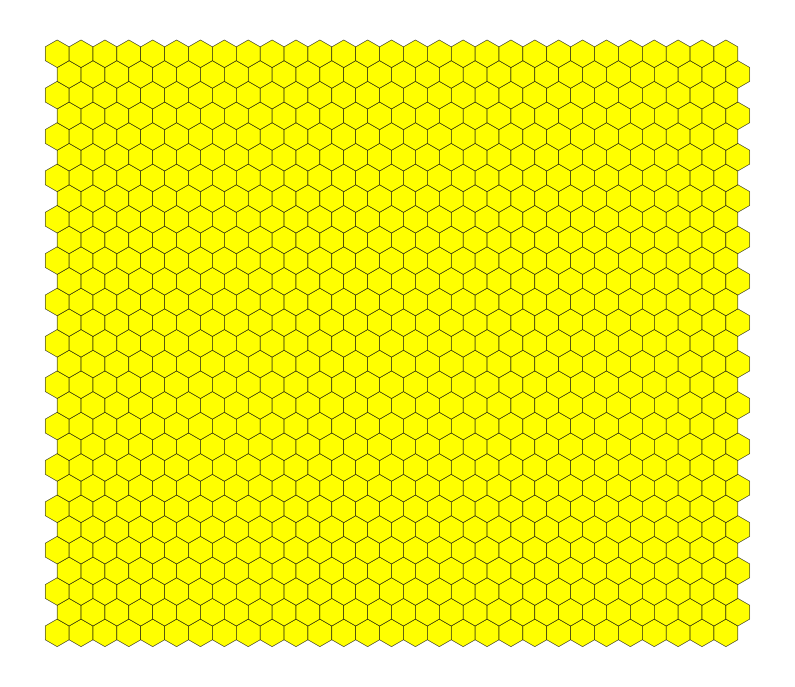

In [59]:
def make_comb():

    hexagons_flat = [
        hexagons[j][i]
        for j in range(rows)
        for i in range(cols)
    ]

    colors_flat = matrix_color.ravel()
    fig, ax = plt.subplots(figsize=(10, 10))

    collection = PolyCollection(
        hexagons_flat,
        facecolors=colors_flat,
        edgecolors="black",
        linewidths=0.35,
    )

    ax.add_collection(collection)
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.axis("off")
    plt.show()

make_comb()




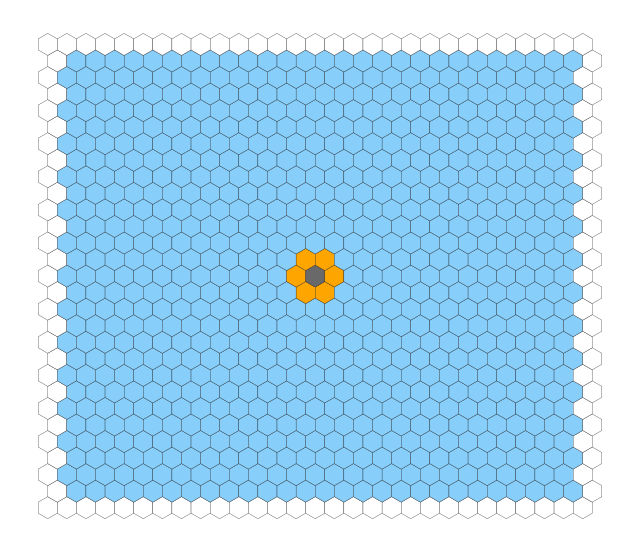

In [ ]:

alpha = 0.1
beta = 0.0
gamma = 0.01

N, B, F, E = 0, 1, 2, 3

state = np.full((rows, cols), N, dtype=int)

u = np.zeros((rows, cols), dtype=float)
v = np.zeros((rows, cols), dtype=float)

cy, cx = rows // 2, cols // 2
state[cy, cx] = F

state[0, :] = E
state[-1, :] = E
state[:, 0] = E
state[:, -1] = E

def get_neighbors(j, i):
    if j % 2 == 0:
        positions = [
            (j, i - 1), (j, i + 1),
            (j - 1, i - 1), (j - 1, i),
            (j + 1, i - 1), (j + 1, i),
        ]
    else:
        positions = [
            (j, i - 1), (j, i + 1),
            (j - 1, i), (j - 1, i + 1),
            (j + 1, i), (j + 1, i + 1),
        ]

    return [
        (y, x) for y, x in positions
        if 0 <= y < rows and 0 <= x < cols
    ]


for j in range(1, rows - 1):
    for i in range(1, cols - 1):
        if state[j, i] == N:
            if any(state[y, x] == F
                   for y, x in get_neighbors(j, i)):
                state[j, i] = B


def model_step(state, u, v):
    new_u = u.copy()
    new_v = v.copy()
    new_u[state == E] = beta

    for j in range(1, rows - 1):
        for i in range(1, cols - 1):

            neighbors = get_neighbors(j, i)

            if state[j, i] == N:
                n_values = [
                    u[y, x] for y, x in neighbors
                    if state[y, x] == N
                ]

                if n_values:
                    avg_u = np.mean(n_values)
                    new_u[j, i] = u[j, i] + (
                        2 * alpha / 3
                    ) * (avg_u - u[j, i])

            elif state[j, i] == B:
                n_values = [
                    u[y, x] for y, x in neighbors
                    if state[y, x] == N
                ]

                avg_u = np.mean(n_values) if n_values else 0.0

                new_v[j, i] = v[j, i] + gamma + (
                    2 * alpha / 3
                ) * avg_u

    s = new_u + new_v

    new_state = state.copy()
    new_state[(state == B) & (s >= 1.0)] = F

    for j in range(1, rows - 1):
        for i in range(1, cols - 1):
            if new_state[j, i] in (N, B):
                touches_fixed = any(
                    new_state[y, x] == F
                    for y, x in get_neighbors(j, i)
                )
                new_state[j, i] = B if touches_fixed else N

    return new_state, new_u, new_v


state, u, v = model_step(state, u, v)

color_map = {
    N: "lightskyblue",
    B: "orange",
    F: "dimgray",
    E: "white",
}

matrix_color = np.array(
    [color_map[value] for value in state.ravel()],
    dtype=object
)

fig, ax = plt.subplots(figsize=(8, 8))
collection = PolyCollection(
    [hexagons[j][i] for j in range(rows) for i in range(cols)],
    facecolors=matrix_color,
    edgecolors="black",
    linewidths=0.2,
)
ax.add_collection(collection)
ax.autoscale_view()
ax.set_aspect("equal")
ax.axis("off")
plt.show()
